# Dar_022 — Hard/soft environmental rule influence and notebook lineage

**Objective:** environmental evidence for choosing a lunar base location together with terrain. This follows the original notebooks 31–32 diagnostic/comparison/interpretation flow, without changing their code, CNN artifacts or protected reserves.

## Questions and prior evidence

- Q25: How many analysis units meet each declared diagnostic threshold combination?
- Q26: Which marginal condition limits availability, and does the joint result differ?
- Q27: Does filtering only an existing top five hide otherwise qualifying units?
- Q28: Are missing metrics retained as Unknown rather than zero or automatic failure?
- Q29: Do positive-spot and fixed-common observation cohorts alter diagnostic availability?
- Q30: Which actual operational requirements remain unresolved despite these environmental data?
- Q31: How do these outputs follow the original EDA-to-decision notebook pattern?
- Q32: What tested implementation primitives and next decisions follow without claiming a deployed engine?

Read the accepted Dar_017/018 results before interpreting these extensions. The questions are related diagnostics, not independent experiments.

## Input contract and declared considerations

Hold candidate pools fixed. Compare all 27 proxy threshold combinations, diagnostic weights (0.25,0.25,0.5), gate-before-top-five versus late filtering, and alternative observation cohorts. These are explicitly non-adopted proxy scenarios, not mission requirements. Diagnostic conjunction has known-failure precedence; otherwise missing required evidence remains Unknown. Actual operational readiness remains separate and Unknown.

In [1]:
from pathlib import Path
import sys,json
from itertools import product
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0]=[str(ROOT/'darrel stuff/EDA'),str(ROOT)]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from environment_workflow import LocalRun as Run,latest_completed_run
from decision_eda import accepted_input
from environmental_selection_eda import *
import environmental_selection_eda as methods
DATA=ROOT/'darrel stuff/data'
REGION_LIMIT=None  # Set 1 for the initial representative sample, None for all seven.
JOINT_RUN_ID='20261106T134155791814Z_c6f9ab'
joint=latest_completed_run(ROOT,'analysis/dar_012_joint_environment',JOINT_RUN_ID)
def savefig(run,fig,name):
    fig.savefig(run.path(name+'.png'),dpi=125,bbox_inches='tight');display(fig);plt.close(fig)
def register_methods(run):
    run.input(Path(methods.__file__))
    for name in ['moon_p1_analysis.py','site_comparison.py','decision_eda.py']:
        run.input(ROOT/'darrel stuff/EDA'/name)
    for name in ['31_vertical_scale_sensitivity.ipynb','32_candidate_coverage_and_ranking.ipynb']:
        run.input(ROOT/'notebooks/modeling/terrain_similarity'/name)
def publish(run,record):
    run.path('findings.json').write_text(json.dumps(record,indent=2,default=str),encoding='utf-8')
    display(record)
def selected_regions(values):
    regions=sorted(values)
    if REGION_LIMIT is not None:
        if type(REGION_LIMIT) is not int or not 1<=REGION_LIMIT<=len(regions):raise ValueError('Invalid region sample')
        regions=regions[:REGION_LIMIT]
    return regions

Accepted local analysis/dar_012_joint_environment run: 20261106T134155791814Z_c6f9ab


In [2]:
PREFERENCE_RUN_ID=None  # Set an accepted run ID for exact reproduction.

## Build a new local run and compare the data

Inputs and helper source hashes are recorded. Results remain under `darrel stuff/data/processed/analysis/`; source downloads and earlier notebooks are not overwritten.

Accepted local analysis/dar_021_preference_influence run: 20261107T160114078229Z_2bffc2


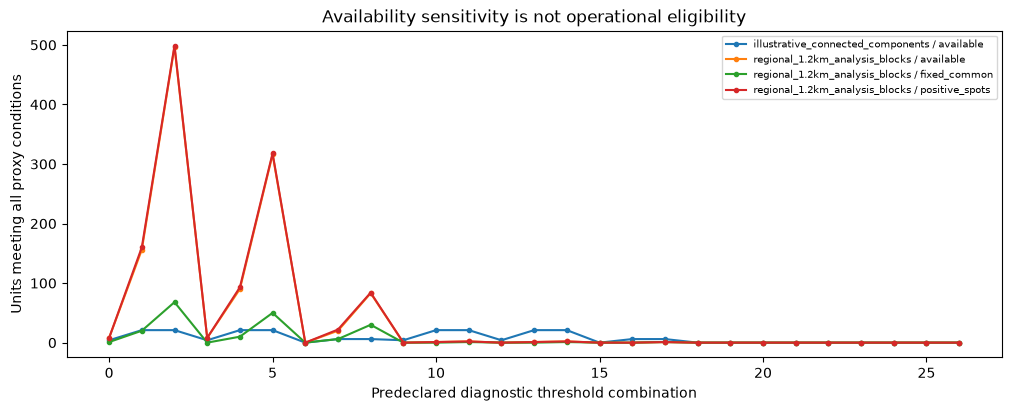

,solar_min,earth_min,slope_q90_max_deg,pool_units,diagnostic_met,diagnostic_not_met,unknown,ungated_top5_met,gate_first_top5_count,eligible_hidden_by_late_top5_filter,policy_adopted,operational_status,pool,cohort
0,0.25,0.25,5.0,21,4,17,0,0,4,4,False,Unknown,illustrative_connected_components,available
1,0.25,0.25,10.0,21,21,0,0,5,5,0,False,Unknown,illustrative_connected_components,available
2,0.25,0.25,15.0,21,21,0,0,5,5,0,False,Unknown,illustrative_connected_components,available
3,0.25,0.50,5.0,21,4,17,0,0,4,4,False,Unknown,illustrative_connected_components,available
4,0.25,0.50,10.0,21,21,0,0,5,5,0,False,Unknown,illustrative_connected_components,available
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,0.75,0.50,10.0,2430,0,500,1930,0,0,0,False,Unknown,regional_1.2km_analysis_blocks,fixed_common
104,0.75,0.50,15.0,2430,0,500,1930,0,0,0,False,Unknown,regional_1.2km_analysis_blocks,fixed_common
105,0.75,0.75,5.0,2430,0,500,1930,0,0,0,False,Unknown,regional_1.2km_analysis_blocks,fixed_common
106,0.75,0.75,10.0,2430,0,500,1930,0,0,0,False,Unknown,regional_1.2km_analysis_blocks,fixed_common


,region,requirement,status,reason_code,operational_score
0,A3CLR22_10_Leibnitz_Beta_Plateau,power_endurance,Unknown,DATED_TERRAIN_ILLUMINATION_AND_HARDWARE_REQUIRED,NaN
1,A3CLR22_10_Leibnitz_Beta_Plateau,component_thermal_margin,Unknown,APPLICABLE_COMPONENT_RESPONSE_AND_LIMITS_REQUIRED,NaN
2,A3CLR22_10_Leibnitz_Beta_Plateau,communications_continuity,Unknown,DATED_GEOMETRY_ARCHITECTURE_AND_LINK_REQUIREME...,NaN
3,A3CLR22_10_Leibnitz_Beta_Plateau,radiation_protection,Unknown,APPLICABLE_SURFACE_FIELD_TRANSPORT_AND_LIMITS_...,NaN
4,A3CLR22_10_Leibnitz_Beta_Plateau,base_footprint_requirement,Unknown,LAYOUT_SIZE_TERRAIN_POLICY_AND_LOCAL_VALIDATIO...,NaN
5,A3CLR22_11_Malapert_Massif,power_endurance,Unknown,DATED_TERRAIN_ILLUMINATION_AND_HARDWARE_REQUIRED,NaN
6,A3CLR22_11_Malapert_Massif,component_thermal_margin,Unknown,APPLICABLE_COMPONENT_RESPONSE_AND_LIMITS_REQUIRED,NaN
7,A3CLR22_11_Malapert_Massif,communications_continuity,Unknown,DATED_GEOMETRY_ARCHITECTURE_AND_LINK_REQUIREME...,NaN
8,A3CLR22_11_Malapert_Massif,radiation_protection,Unknown,APPLICABLE_SURFACE_FIELD_TRANSPORT_AND_LIMITS_...,NaN
9,A3CLR22_11_Malapert_Massif,base_footprint_requirement,Unknown,LAYOUT_SIZE_TERRAIN_POLICY_AND_LOCAL_VALIDATIO...,NaN


**Observed influence:** filtering a preselected top five can hide qualifying proxy candidates. The gate-first comparison tests this directly; all 35 actual operational readiness records remain Unknown because required scenario/design inputs are not supplied.

{'questions': ['Q25', 'Q26', 'Q27', 'Q28', 'Q29', 'Q30', 'Q31', 'Q32'],
 'regions': 7,
 'diagnostic_gate_summary_rows': 108,
 'late_filter_misses_by_pool': [{'pool': 'illustrative_connected_components',
   'sum': 16,
   'max': 4},
  {'pool': 'regional_1.2km_analysis_blocks', 'sum': 20, 'max': 5}],
 'scenarios_with_no_diagnostic_matches': 56,
 'actual_requirement_status_counts': {'Unknown': 35},
 'operational_scores_computed': 0,
 'limits': ['DiagnosticMet/DiagnosticNotMet are not operational Passed/Failed',
  'A known proxy violation establishes DiagnosticNotMet even when another proxy is missing; otherwise incomplete inputs remain Unknown',
  'Block medians and slope q90 are not full-footprint guarantees',
  'No real mission requirements or preference weights adopted']}

In [3]:
preference=latest_completed_run(ROOT,'analysis/dar_021_preference_influence',PREFERENCE_RUN_ID)
with Run(ROOT,'analysis/dar_022_rule_influence',{'region_limit':REGION_LIMIT,'preference_run':str(preference.relative_to(ROOT)),
    'diagnostic_thresholds':list(product([.25,.5,.75],[.25,.5,.75],[5.,10.,15.])),
    'diagnostic_weights':[.25,.25,.5],'adopted_operational_rules':None,'actual_preference_score':None},
    'Moon/Site_Assessment/Dar_022_environment_hard_soft_rule_influence.ipynb') as run:
    register_methods(run)
    pool=pd.read_csv(accepted_input(run,preference,'comparison_units.csv'))
    regions=selected_regions(pool.region.unique());pool=pool.loc[pool.region.isin(regions)]
    rank=pd.read_csv(accepted_input(run,preference,'diagnostic_preference_scenarios.csv.gz'))
    summaries=[];details=[];bottlenecks=[]
    for family,part in pool.groupby('pool'):
        p=rank.loc[rank.pool.eq(family)&rank.region.isin(regions)]
        summary,detail=gate_scenarios(part,p);summary['pool']=family;summary['cohort']='available'
        summaries.append(summary)
        if len(detail):detail['pool']=family;details.append(detail)
        finite=np.isfinite(part[METRICS]).all(axis=1)
        measured=part.loc[finite]
        for a,b,c in product([.25,.5,.75],[.25,.5,.75],[5.,10.,15.]):
            masks=[measured.solar_fraction.ge(a),measured.earth_fraction.ge(b),measured.slope_deg.le(c)]
            bottlenecks.append({'pool':family,'solar_min':a,'earth_min':b,'slope_q90_max_deg':c,'finite_units':len(measured),
                'solar_met':int(masks[0].sum()),'earth_met':int(masks[1].sum()),'slope_met':int(masks[2].sum()),
                'all_met':int((masks[0]&masks[1]&masks[2]).sum())})
    blocks=pd.read_csv(accepted_input(run,joint,'candidate_block_context.csv'));blocks=blocks.loc[blocks.region.isin(regions)]
    centers=pd.read_csv(accepted_input(run,joint,'native_center_context.csv.gz'));centers=centers.loc[centers.region.isin(regions)]
    for cohort,part in [('positive_spots',centers.loc[centers.spot_count.gt(0)]),('fixed_common',centers.loc[centers.complete_common_cohort])]:
        alternative=comparison_pool(blocks,part)
        summary,_=gate_scenarios(alternative,preference_scenarios(alternative));summary['pool']='regional_1.2km_analysis_blocks';summary['cohort']=cohort;summaries.append(summary)
    summary=pd.concat(summaries,ignore_index=True);ready=requirement_readiness(regions)
    summary.to_csv(run.path('diagnostic_hard_gate_scenarios.csv'),index=False)
    pd.DataFrame(bottlenecks).to_csv(run.path('marginal_and_joint_rule_availability.csv'),index=False)
    pd.concat(details,ignore_index=True).to_csv(run.path('gate_before_top5_examples.csv'),index=False)
    ready.to_csv(run.path('actual_operational_requirement_readiness.csv'),index=False)
    lineage=pd.DataFrame([
        {'reference':'31_vertical_scale_sensitivity','pattern':'declared intervention, fixed inputs, identity controls, sensitivity not improvement',
         'environmental_implementation':'grid/origin/connectivity controls and explicit weight/normalization scenarios; no best setting selected'},
        {'reference':'32_candidate_coverage_and_ranking','pattern':'availability separate from ranking; same fixed pool; no-match retained',
         'environmental_implementation':'gate-first versus late-top-five filtering on the same units; empty/Unknown support retained'},
        {'reference':'Dar_017/018','pattern':'joint native-center evidence with phase/cohort and source constraints',
         'environmental_implementation':'separate connected-lattice and 1.2 km center-context pools; no fabricated footprint/mission transfer'}])
    lineage.to_csv(run.path('eda_to_algorithm_lineage.csv'),index=False)
    fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
    for (family,cohort),p in summary.groupby(['pool','cohort']):ax.plot(range(len(p)),p.diagnostic_met,marker='.',label=family+' / '+cohort)
    ax.set(xlabel='Predeclared diagnostic threshold combination',ylabel='Units meeting all proxy conditions',title='Availability sensitivity is not operational eligibility');ax.legend(fontsize=7)
    savefig(run,fig,'hard_gate_and_cohort_sensitivity')
    display(summary);display(ready)
    display(Markdown('**Observed influence:** filtering a preselected top five can hide qualifying proxy candidates. The gate-first comparison tests this directly; all '+str(len(ready))+' actual operational readiness records remain Unknown because required scenario/design inputs are not supplied.'))
    adopted={'operational_rules':None,'operational_scores':None,'status':'Unknown',
        'diagnostic_rule_values_are_not_adopted':True,'missing_is_not_pass':True,
        'handoff':['unit identity and support','applicability and source provenance','documented mandatory comparison',
                   'Failed/Unknown reasons','configured preferences only after all applicable mandatory passes']}
    run.path('rule_handoff_contract.json').write_text(json.dumps(adopted,indent=2),encoding='utf-8')
    publish(run,{'questions':['Q%02d'%i for i in range(25,33)],'regions':len(regions),'diagnostic_gate_summary_rows':len(summary),
        'late_filter_misses_by_pool':summary.loc[summary.cohort.eq('available')].groupby('pool').eligible_hidden_by_late_top5_filter.agg(['sum','max']).reset_index().to_dict('records'),
        'scenarios_with_no_diagnostic_matches':int(summary.diagnostic_met.eq(0).sum()),
        'actual_requirement_status_counts':ready.status.value_counts().to_dict(),'operational_scores_computed':0,
        'limits':['DiagnosticMet/DiagnosticNotMet are not operational Passed/Failed',
        'A known proxy violation establishes DiagnosticNotMet even when another proxy is missing; otherwise incomplete inputs remain Unknown',
        'Block medians and slope q90 are not full-footprint guarantees','No real mission requirements or preference weights adopted']})
OUT=run.directory

## Findings and observed influence

Read the executed `findings.json`, tables and plots above; counts and missing groups are part of the result. An observed rank/availability change is sensitivity under the declared controls, not evidence that the changed setting is correct.

## Effect on hard rules and soft preferences

This implements and tests reusable evidence/gate/preference diagnostics, not integration into the original CNN demo or a completed mission engine. The proposed handoff is evidence > applicable mandatory checks > Failed/Unknown explanation > eligible preferences > location report. Recover/configure mission-specific inputs before operational scoring.

## Implementation handoff and next decision

Reuse the functions in `../../environmental_selection_eda.py` and retain source/assessment-unit contracts. Compare available evidence before adopting any rule. See [EDA work plan and questions](../../EDA_Notes.md#eda-question-register), [EDA results](../../EDA_Results.md) and [the proposal](../../../Brief_Overview.md#algorithm-proposal) for the full EDA → influence → proposed implementation chain. Exact CNN-patch matching remains optional; local, regional and reference evidence must not be conflated.

## Save reusable data and disposable reports

The completed run above already saved reusable tables, plots, `findings.json` and provenance together. Later notebooks read accepted table exports rather than notebook display outputs. Clear/regenerate disposable reports only if intended; no source data were deleted.